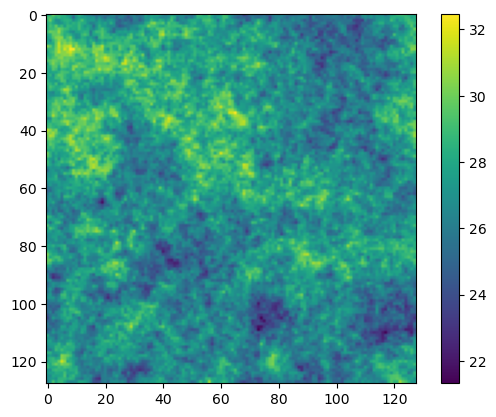

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "config.yml").exists())   # project root (works from notebooks/ or the root)

image = np.load(ROOT / 'data/image.npy')
obsimage = np.load(ROOT / 'data/obsx_obs.npy')

plt.imshow(image)
plt.colorbar()


Text(0.5, 1.0, 'observed image (subset 0)')

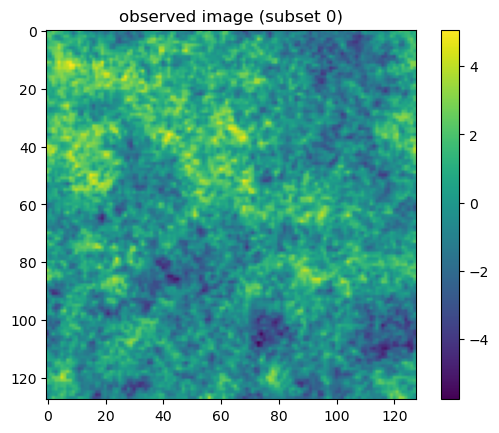

In [2]:
# obsimage is real: the dirty image of the Hermitian, gain-scaled UV data (src/model.DirtyImageFromUV).
plt.imshow(obsimage[0].real)
plt.colorbar()
plt.title('observed image (subset 0)')

## Reconstructing the original image

The observed image is produced by a **known, linear, on-grid** operator:

$$\mathrm{obs}_s = \mathcal{F}^{-1}\!\big(M_s \cdot \mathcal{F}(\mathrm{image})\big), \qquad M_s = \frac{\mathrm{stacked\_uv}_s}{\mathrm{unit\_uv}_s}$$

where $M_s$ is a **complex** mask per subset = (UV sampling support) $\times$ (antenna-gain scaling). Because the data already sits on the uniform $128\times128$ FFT grid, this is a **masked / gain-scaled Fourier inversion**, *not* an off-grid problem — so a non-uniform DFT (NUDFT) / gridding step is unnecessary. Recovery hinges on how much of $M$ you know:

1. **Oracle** — $M$ (gains) known → divide and zero-fill missing UV. *(upper bound)*
2. **Dirty** — only the sampling support known → ignore gains, inverse-FFT the zero-filled data.
3. **Self-cal** — support known + a reference calibrator → estimate the gains from $V_\mathrm{ref}=G\,S_\mathrm{ref}\,G^\dagger$, then invert.

About 76.5% of the 128² UV cells are sampled (both subsets together; printed below), the long baselines and the outer UV plane are not. The DC cell is never sampled (`drop_dc`), so every reconstruction is zero-mean and is compared against the mean-subtracted image `image0`.

In [3]:
# ============================================================
# Reconstruction setup - common pieces
# ============================================================
# Forward model used to generate the data (see scripts/gen_mock_data.py, src/model.py):
#   uvimage      = func.image_to_uv(image)  = fft2(ifftshift(image), norm="ortho")
#   x_obs[s]     = M[s] * uvimage          with  M[s] = stacked_uv[s] / unit_uv[s]
#   obsimage[s]  = func.uv_to_image(x_obs[s]) = fftshift(ifft2(x_obs[s], norm="ortho"))
# Below, np.fft.fft2(obsimage, norm='ortho') = x_obs * (-1)^(u+v) (N even); dividing by M and
# applying np.fft.ifft2(..., norm='ortho') then returns the image in the same (centred) pixel frame as `image`.
# M[s] is a COMPLEX mask = (UV sampling support) x (antenna-gain scaling), per subset s.
# The data lives on a uniform 128x128 grid -> masked/gain-scaled Fourier inversion,
# NOT an off-grid problem, so plain NUDFT/gridding is unnecessary.

import sys, torch
sys.path.insert(0, str(ROOT / 'src'))
import functionlistnew as func

device = 'cuda' if torch.cuda.is_available() else 'cpu'
import settings
padded = torch.load(settings.PADDED_PATH, map_location=device, weights_only=True)
nant   = func.nant_from_padded(padded)   # 46971 baselines -> 307 antennas
N = settings.N_PIX
knownant = settings.KNOWN_ANT            # the last 200 antennas have known unit gain (as in src/model.py)
subsetindex = func.split_indices(padded.shape[0], settings.N_SUBSETS)
config = func.SimulationConfig(nant=nant, padded=padded, subsetindex=subsetindex,
                               device=device)   # grid / calibrator defaults: src/settings.py
UV_gen   = func.UVMapGenerator(config)
Unit_gen = func.UnitUVMapGenerator(config)

unit_uv = Unit_gen()                          # (1, 2, N, N) complex
support = np.abs(unit_uv[0].cpu().numpy()) > 1e-12  # (2, N, N) bool - the "identity" of M (known)

# Back to the UV (Fourier) domain: x_obs[s] = M[s] * fft2(image)
x_obs = np.fft.fft2(obsimage, norm='ortho')   # (2, N, N) complex

def invert_with_M(M):
    """Recover image given the complex mask M (2, N, N): divide on sampled cells,
    average the two subsets, zero-fill the unsampled cells (~25%)."""
    uv  = np.zeros((N, N), complex)
    cnt = np.zeros((N, N))
    for s in range(2):
        sel = support[s]
        uv[sel]  += x_obs[s][sel] / M[s][sel]
        cnt[sel] += 1
    cnt[cnt == 0] = 1
    uv /= cnt
    return np.real(np.fft.ifft2(uv, norm='ortho'))

# DC is not sampled (drop_dc) -> reconstructions are zero-mean; compare to mean-subtracted truth
image0 = image - image.mean()
relerr = lambda r: np.linalg.norm(r - image0) / np.linalg.norm(image0)

print(f"UV sampling: {support.any(0).sum()} / {N*N} cells "
      f"({100*support.any(0).mean():.1f}%) across the 2 subsets")

UV sampling: 12534 / 16384 cells (76.5%) across the 2 subsets


In [4]:
# ============================================================
# Setup 1 - ORACLE: complex scaling M is KNOWN (gains calibrated)
# ============================================================
# Upper bound on achievable quality. Uses the true antenna gains (true_z) only to
# build M exactly as the simulator did; in practice M would come from calibration.
true_gains = func.theta_to_gains(torch.from_numpy(np.load(ROOT / 'data/true_z.npy')), knownant)
M_oracle   = torch.nan_to_num(UV_gen(true_gains) / unit_uv, nan=0.0)[0].cpu().numpy()

rec_oracle = invert_with_M(M_oracle)
print(f"Setup 1  ORACLE (M known)      rel L2 error = {relerr(rec_oracle):.4f}")

Setup 1  ORACLE (M known)      rel L2 error = 0.1317


In [5]:
# ============================================================
# Setup 2 - gains UNKNOWN, only the sampling support is known
# ============================================================
# Best linear estimate without the complex scaling: zero-fill the observed UV data
# on the known support and inverse-FFT -> the interferometric "dirty image".
# Deconvolution (e.g. CLEAN) could fill the missing ~23.5% of UV cells, but it CANNOT
# undo the unknown gain corruption, so the error here is gain-limited.
uv  = np.zeros((N, N), complex)
cnt = np.zeros((N, N))
for s in range(2):
    sel = support[s]
    uv[sel]  += x_obs[s][sel]
    cnt[sel] += 1
cnt[cnt == 0] = 1
uv /= cnt
rec_dirty = np.real(np.fft.ifft2(uv, norm='ortho'))
print(f"Setup 2  DIRTY (gains ignored) rel L2 error = {relerr(rec_dirty):.4f}")

Setup 2  DIRTY (gains ignored) rel L2 error = 0.1423


In [6]:
# ============================================================
# Setup 3 - JOINT self-calibration: estimate gains, then invert
# ============================================================
# Use the known reference calibrator: V_ref[i,j] = g_i * conj(g_j) * S_ref[i,j].
# So R = V_ref / S_ref is a rank-1 matrix  g g^H  on the valid baselines.
# Recover antenna gains g by a weighted rank-1 fit (alternating least squares),
# fixing g_0 = 1 (the gauge used in theta_to_gains) and the KNOWN antennas (the last knownant)
# at g = 1, as the pipeline assumes; then rebuild M from them.
S_ref = np.load(ROOT / 'data/S_ref.npy')        # (N,N) known calibrator coherence
V_ref = np.load(ROOT / 'data/V_ref_obs.npy')    # (N,N) observed reference visibility

Wt = (np.abs(S_ref) > 1e-8).astype(float)                      # valid-baseline weights
np.fill_diagonal(Wt, 0.0)
R  = np.where(Wt > 0, V_ref / np.where(Wt > 0, S_ref, 1), 0.0)  # = g_i conj(g_j)

g = np.ones(nant, complex)
for _ in range(200):                                            # weighted rank-1 power iteration
    num = (Wt * R) @ g
    den = (Wt * np.abs(g[None, :])**2).sum(1)
    g   = num / np.where(den > 0, den, 1)
    g   = g / g[0]                                              # gauge: g_0 = 1
    g[nant - knownant:] = 1.0                                   # known antennas: unit gain

# Rebuild M from the estimated gains, exactly as the simulator does
g_il = torch.zeros(1, 2 * nant)
g_il[0, 0::2] = torch.from_numpy(g.real).float()
g_il[0, 1::2] = torch.from_numpy(g.imag).float()
M_selfcal = torch.nan_to_num(UV_gen(g_il) / unit_uv, nan=0.0)[0].cpu().numpy()

rec_selfcal = invert_with_M(M_selfcal)
g_true = torch.view_as_complex(true_gains.reshape(nant, 2)).numpy()
unknown = slice(1, nant - knownant)                             # the antennas the fit has to find
print(f"Setup 3  SELF-CAL              rel L2 error = {relerr(rec_selfcal):.4f} "
      f"(gain recovery err = {np.linalg.norm(g - g_true) / np.linalg.norm(g_true):.1e}; "
      f"unknown antennas {np.linalg.norm(g[unknown] - g_true[unknown]) / np.linalg.norm(g_true[unknown]):.1e})")

Setup 3  SELF-CAL              rel L2 error = 0.1317 (gain recovery err = 2.5e-09; unknown antennas 4.0e-09)


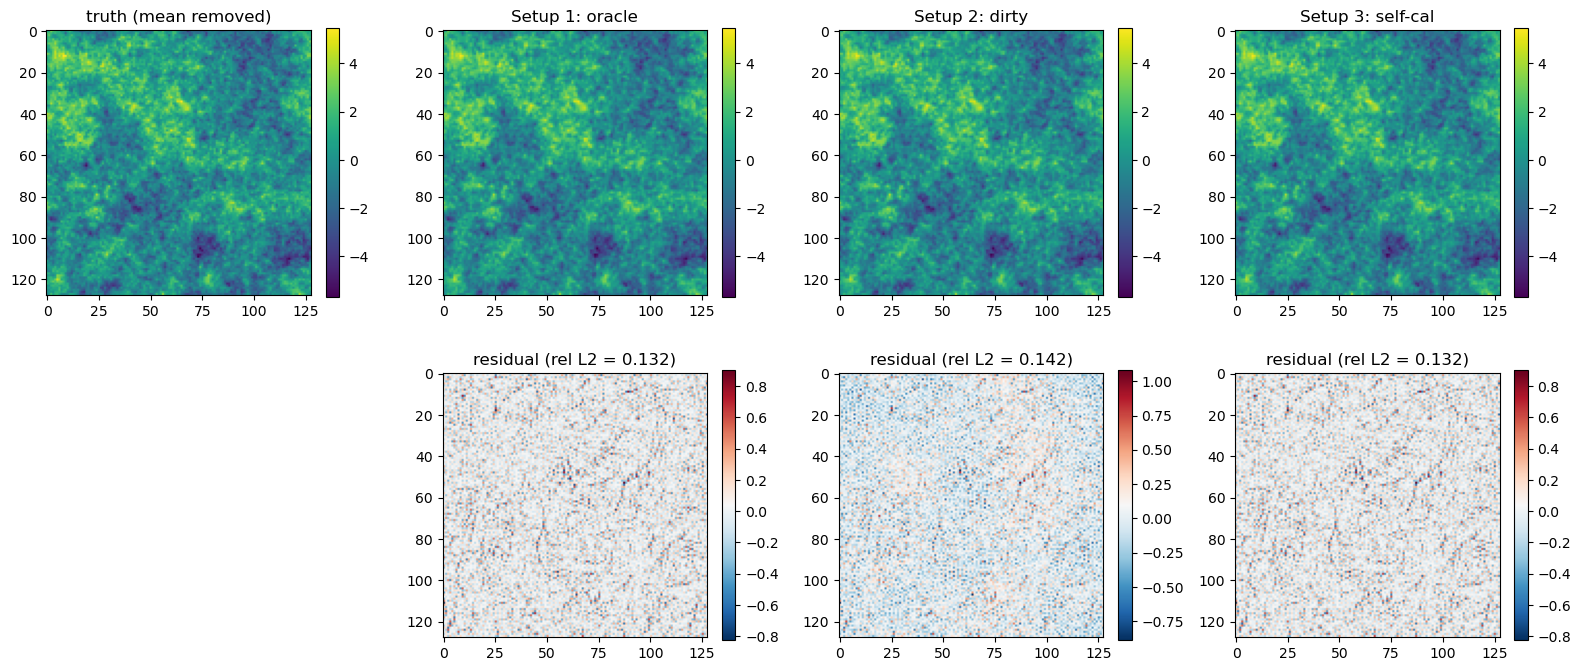

In [7]:
# ============================================================
# Compare all three reconstructions
# ============================================================
recs = [('truth (mean removed)', image0), ('Setup 1: oracle', rec_oracle),
        ('Setup 2: dirty', rec_dirty), ('Setup 3: self-cal', rec_selfcal)]
fig, ax = plt.subplots(2, 4, figsize=(16, 7))
vmin, vmax = image0.min(), image0.max()
for j, (title, r) in enumerate(recs):
    im0 = ax[0, j].imshow(r, vmin=vmin, vmax=vmax); ax[0, j].set_title(title)
    fig.colorbar(im0, ax=ax[0, j], fraction=0.046)
    if j == 0:
        ax[1, j].axis('off')
    else:
        im1 = ax[1, j].imshow(r - image0, cmap='RdBu_r')
        ax[1, j].set_title(f'residual (rel L2 = {relerr(r):.3f})')
        fig.colorbar(im1, ax=ax[1, j], fraction=0.046)
plt.tight_layout()